# Naive Bayes gaussiano

Classificação de churn com o Naive Bayes gaussiano (`GaussianNB`), avaliada com a validação cruzada estratificada de 10 folds comum a todos os algoritmos (`data/processed/folds.csv`).

São quatro configurações, todas com idade numérica, nas bases com e sem `inativo`. As três primeiras usam priors uniformes (0,5 / 0,5):
- **completo**: todos os atributos, com `log1p`;
- **sem redundantes**: sem `segundos_uso`, para medir o efeito da redundância na suposição de independência;
- **sem `log1p`**: atributos de uso na escala original, para medir o efeito do log na suposição de normalidade;
- **priors da base**: igual à completa, mas com os priors estimados no treino (~0,84 / 0,16, o padrão do `GaussianNB`), para medir o efeito do desbalanceamento.

## Como o Naive Bayes funciona

O Naive Bayes é um classificador probabilístico baseado no **teorema de Bayes**. Para um cliente com atributos $x = (x_1, \dots, x_d)$, a probabilidade a posteriori de cada classe $c$ (churn ou não churn) é

$$P(c \mid x) = \frac{P(c)\, P(x \mid c)}{P(x)} \propto P(c) \prod_{i=1}^{d} P(x_i \mid c).$$

- **Suposição "ingênua"**: dentro de cada classe, os atributos são independentes entre si. É ela que permite escrever $P(x \mid c)$ como o produto das verossimilhanças de cada atributo, em vez de estimar a distribuição conjunta de todos, o que exigiria muito mais dados.
- **Versão gaussiana**: cada $P(x_i \mid c)$ é uma normal com média $\mu_{ic}$ e variância $\sigma^2_{ic}$, estimadas no treino com os clientes da classe $c$:
  $$P(x_i \mid c) = \frac{1}{\sqrt{2\pi\sigma^2_{ic}}} \exp\!\left(-\frac{(x_i - \mu_{ic})^2}{2\sigma^2_{ic}}\right).$$
- **Treino**: consiste só em calcular, para cada classe, a média e a variância de cada atributo (e os priors $P(c)$, se não forem fixados). Não há otimização iterativa.
- **Decisão**: o cliente recebe a classe de maior posterior. Em termos de chance, $\frac{P(\text{churn} \mid x)}{P(\text{não churn} \mid x)} = \frac{P(\text{churn})}{P(\text{não churn})} \prod_i \frac{P(x_i \mid \text{churn})}{P(x_i \mid \text{não churn})}$: cada atributo contribui com uma razão de verossimilhança, e as contribuições se multiplicam.
- **`var_smoothing`**: soma a todas as variâncias uma fração da maior variância entre os atributos, para evitar divisões por variâncias próximas de zero.

## Por que o Naive Bayes neste problema

- **Linha de base probabilística simples**: não tem hiperparâmetros de capacidade, treina instantaneamente e fornece probabilidades para o log loss e a PR-AUC. Serve de referência para medir quanto os modelos mais complexos (MLP, XGBoost) acrescentam.
- **Interpretável**: as médias e variâncias por classe mostram diretamente como os clientes churn diferem dos que ficam, e as razões de verossimilhança dizem quanto cada atributo pesa na decisão.
- **Testa a suposição de independência**: a análise exploratória encontrou atributos fortemente correlacionados (segundos × ligações, r = 0,925 após o log). O NB é o algoritmo em que essa redundância mais interfere, porque conta duas vezes a mesma evidência. Isso torna o efeito mensurável, comparando as configurações com e sem `segundos_uso`.
- **Bom com poucos dados por classe**: estima só 2 parâmetros por atributo e por classe, o que é estável mesmo com os 446 churns.

## Pré-processamento necessário para o Naive Bayes

| etapa | onde é feita | por que o NB precisa (ou não) |
|---|---|---|
| `log1p` nos 6 atributos de uso | base inteira (`pre-processamento.ipynb`) | o NB gaussiano supõe que cada atributo é normal dentro de cada classe. Os atributos de uso têm cauda longa à direita, e o log os aproxima da normal. A configuração **sem `log1p`** desfaz o log (`expm1`) para medir esse efeito |
| **idade numérica (sem one-hot)** | neste notebook, reconstruída a partir das 5 colunas one-hot | com média e variância próprias por classe, duas gaussianas já representam o churn concentrado nas idades do meio: se a gaussiana do churn é mais estreita e centrada no meio, a razão entre as duas tem um pico ali. Já o one-hot criaria 5 colunas dependentes entre si (exatamente uma vale 1), violando a independência, e cada uma seria um binário tratado como gaussiano |
| sem padronização | — | a média e a variância de cada atributo absorvem a escala, e a verossimilhança de cada um é calculada na sua própria escala. Com o `var_smoothing` desprezível (1e-9), padronizar não altera as decisões |
| priors 0,5 / 0,5 | parâmetro do modelo | o NB não tem pesos de classe; o equivalente é fixar priors uniformes, para que a decisão dependa só da evidência dos atributos. A justificativa e o efeito esperado estão em `consideracoes.md` ("Naive Bayes com priors 0,5 / 0,5") |

**Limitação**: os binários (`reclamacao`, `plano_contratual`, `inativo`) continuam tratados como gaussianos, uma aproximação grosseira para variáveis 0/1. Um NB misto (categórico nos discretos e gaussiano nos contínuos) não existe pronto no scikit-learn e ficou fora do escopo.

As duas transformações deste notebook (idade numérica e `expm1`) tratam cada linha isoladamente, então são feitas na base inteira, sem vazamento entre treino e teste.

## Parâmetros

O `GaussianNB` tem só dois parâmetros:

| parâmetro | valor | justificativa |
|---|---|---|
| `priors` | `[0.5, 0.5]` nas configurações principais; os priors da base (`None`, estimados no treino de cada fold) na configuração `priors-base` | sem eles, o modelo parte da proporção do treino (~84% / 16%), e a evidência de um cliente precisa superar uma vantagem de ~5,4 para 1 a favor de "não churn", o que derruba o recall, a métrica principal. Os priors uniformes seguem o mesmo princípio dos pesos "balanced" dos outros algoritmos |
| `var_smoothing` | `1e-9` (padrão) | só garante estabilidade numérica. Valores maiores seriam proporcionais à maior variância entre os atributos e, sem padronização, suavizariam muito mais os atributos de variância pequena (os binários) do que os outros |

A configuração `priors-base` é a variação de **parâmetro** do modelo: só os priors mudam em relação à `completo`. As outras duas variam **os atributos que o modelo recebe** (com ou sem o redundante, com ou sem `log1p`), pondo à prova as duas suposições do NB gaussiano: independência e normalidade.

## Configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.naive_bayes import GaussianNB

from comum import (METRICAS, N_CHURN, N_LINHAS, REDUNDANTES_NB, RESULTS_DIR, avaliar,
                   carregar_base, carregar_folds, idade_numerica, nome_base,
                   registrar_escolhida, salvar_resultados, salvar_tabela,
                   tabela_desbalanceamento)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PRIORS = [0.5, 0.5]
COLS_LOG = ['falhas_ligacao', 'segundos_uso', 'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente']
COLS_LOG_INTEIRAS = [c for c in COLS_LOG if c != 'valor_cliente']  # na base original são contagens
CONFIGS = ['completo', 'sem-redundantes', 'sem-log1p', 'priors-base']
# priors de cada configuração (None = proporção do treino, o padrão do GaussianNB)
PRIORS_CONFIG = {c: (None if c == 'priors-base' else PRIORS) for c in CONFIGS}

## Dados e transformações do notebook

- **Idade numérica**: a coluna com valor 1 entre as 5 do one-hot indica a faixa (15, 25, 30, 45 ou 55 anos).
- **Sem `log1p`**: `expm1` é a inversa exata de `log1p` e devolve os atributos de uso à escala original.

In [2]:
def sem_log1p(X):
    X = X.copy()
    X[COLS_LOG] = np.expm1(X[COLS_LOG])
    assert (X[COLS_LOG] >= -1e-9).all().all()
    for c in COLS_LOG_INTEIRAS:
        assert np.allclose(X[c], X[c].round()), f'{c} deveria voltar a ser inteiro'
        X[c] = X[c].round()
    return X


def atributos(X, config):
    X = idade_numerica(X)
    if config == 'sem-redundantes':
        X = X.drop(columns=REDUNDANTES_NB)
    elif config == 'sem-log1p':
        X = sem_log1p(X)
    return X


bases = {com_status: carregar_base(com_status) for com_status in [True, False]}
y = bases[True][1]
assert np.array_equal(y, bases[False][1])
folds = carregar_folds(y)

for com_status, (X, _) in bases.items():
    for config in CONFIGS:
        print(f'{nome_base(com_status):>10} | {config:<16} | {atributos(X, config).shape[1]} atributos')

com-status | completo         | 12 atributos
com-status | sem-redundantes  | 11 atributos
com-status | sem-log1p        | 12 atributos
com-status | priors-base      | 12 atributos
sem-status | completo         | 11 atributos
sem-status | sem-redundantes  | 10 atributos
sem-status | sem-log1p        | 11 atributos
sem-status | priors-base      | 11 atributos


## Execução

8 rodadas (4 configurações × 2 bases), todas com os mesmos 10 folds.

In [3]:
def criar_nb(priors):
    # devolve a função que o avaliar chama em cada fold
    def criar(y_treino):
        return GaussianNB(priors=priors)
    return criar


linhas, resultados = [], {}
for com_status, (X, y) in bases.items():
    base = nome_base(com_status)
    for config in CONFIGS:
        r = avaliar(criar_nb(PRIORS_CONFIG[config]), atributos(X, config), y, folds)
        assert r['matriz'].sum() == N_LINHAS
        assert r['matriz'][1].sum() == N_CHURN

        resultados[(config, base)] = r
        salvar_resultados(r, 'nb', config, com_status)
        linhas.append(r['por_fold'].reset_index().assign(base=base, config=config))

grade = pd.concat(linhas, ignore_index=True)
assert len(grade) == len(CONFIGS) * 2 * 10

## Resultados

In [4]:
resumo = grade.groupby(['base', 'config'])[METRICAS].agg(['mean', 'std'])
resumo.columns = [f'{m}_{"media" if e == "mean" else "desvio"}' for m, e in resumo.columns]
resumo = resumo.reset_index()
resumo.to_csv(RESULTS_DIR / 'nb-resumo.csv', index=False)

tabela = resumo[['base', 'config']].copy()
for m in METRICAS:
    tabela[m] = resumo[f'{m}_media'].map('{:.3f}'.format) + ' ± ' + resumo[f'{m}_desvio'].map('{:.3f}'.format)
tabela['config'] = pd.Categorical(tabela['config'], CONFIGS)
tabela = tabela.sort_values(['base', 'config']).reset_index(drop=True)
salvar_tabela(tabela, 'nb-tab-resumo')
tabela

,base,config,recall,especificidade,f1_macro,log_loss,pr_auc
0,com-status,completo,0.879 ± 0.040,0.817 ± 0.023,0.752 ± 0.021,1.259 ± 0.359,0.711 ± 0.107
1,com-status,sem-redundantes,0.892 ± 0.047,0.805 ± 0.026,0.745 ± 0.023,1.088 ± 0.264,0.728 ± 0.095
2,com-status,sem-log1p,0.928 ± 0.059,0.634 ± 0.039,0.623 ± 0.023,1.907 ± 0.212,0.686 ± 0.080
3,com-status,priors-base,0.780 ± 0.072,0.865 ± 0.016,0.765 ± 0.032,1.072 ± 0.362,0.712 ± 0.106
4,sem-status,completo,0.774 ± 0.057,0.836 ± 0.013,0.736 ± 0.022,1.120 ± 0.342,0.696 ± 0.110
5,sem-status,sem-redundantes,0.791 ± 0.069,0.802 ± 0.016,0.712 ± 0.027,0.959 ± 0.248,0.710 ± 0.096
6,sem-status,sem-log1p,0.932 ± 0.055,0.602 ± 0.037,0.602 ± 0.024,1.888 ± 0.202,0.669 ± 0.088
7,sem-status,priors-base,0.699 ± 0.080,0.900 ± 0.015,0.772 ± 0.038,0.967 ± 0.343,0.696 ± 0.110


### Matrizes de confusão

Somadas nos 10 folds (cada cliente aparece uma vez, no fold em que estava no teste).

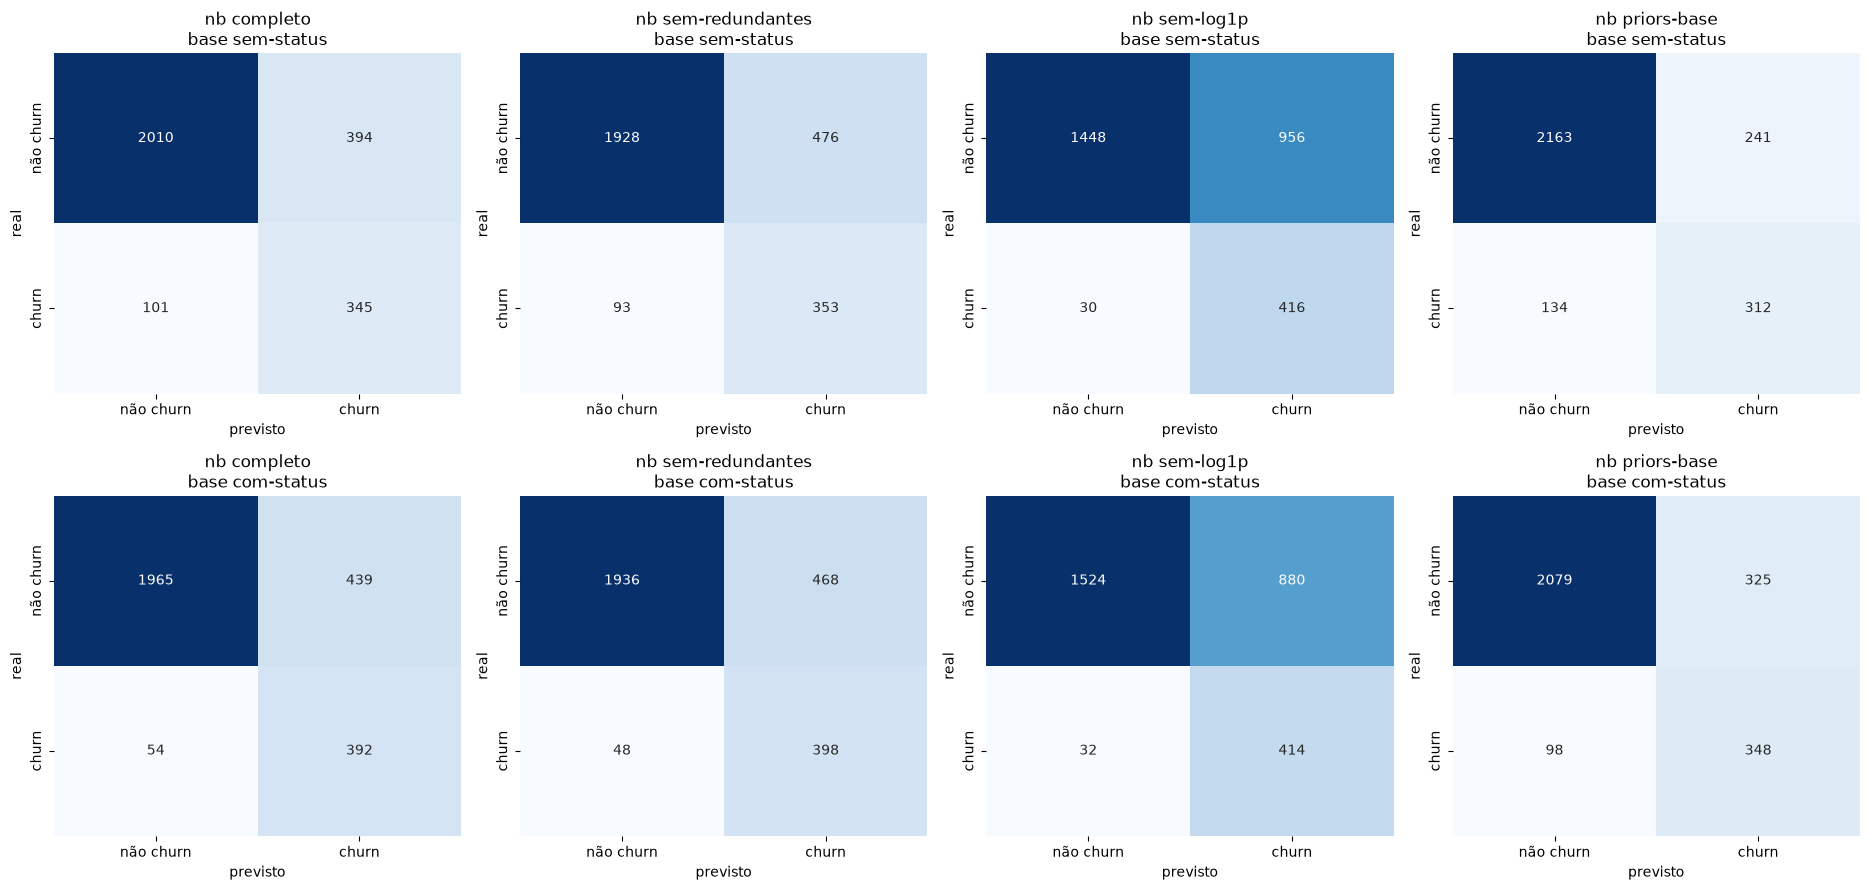

In [5]:
fig, eixos = plt.subplots(2, len(CONFIGS), figsize=(4.7 * len(CONFIGS), 9))
for i, base in enumerate(['sem-status', 'com-status']):
    for j, config in enumerate(CONFIGS):
        ax = eixos[i, j]
        sns.heatmap(resultados[(config, base)]['matriz'], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['não churn', 'churn'], yticklabels=['não churn', 'churn'], ax=ax)
        ax.set_title(f'nb {config}\nbase {base}')
        ax.set_xlabel('previsto')
        ax.set_ylabel('real')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'nb-matrizes-confusao.png', dpi=150, bbox_inches='tight')
plt.show()

### Efeito da redundância e do `log1p` (comparação pareada)

Diferença em relação à configuração **completa**, fold a fold (os folds são os mesmos). Se a diferença média for menor que o seu desvio, o efeito não supera a variação entre folds.

In [6]:
linhas_dif = []
for base in ['sem-status', 'com-status']:
    ref = grade[(grade['base'] == base) & (grade['config'] == 'completo')].set_index('fold')
    for config in ['sem-redundantes', 'sem-log1p']:
        outra = grade[(grade['base'] == base) & (grade['config'] == config)].set_index('fold')
        linha = {'base': base, 'comparação': f'{config} − completo'}
        for m in METRICAS:
            dif = outra[m] - ref[m]
            linha[m] = f'{dif.mean():+.3f} ± {dif.std():.3f}'
        linhas_dif.append(linha)
tab = pd.DataFrame(linhas_dif)
salvar_tabela(tab, 'nb-tab-redundancia-log1p')
tab

,base,comparação,recall,especificidade,f1_macro,log_loss,pr_auc
0,sem-status,sem-redundantes − completo,+0.018 ± 0.018,-0.034 ± 0.010,-0.024 ± 0.009,-0.161 ± 0.121,+0.014 ± 0.033
1,sem-status,sem-log1p − completo,+0.159 ± 0.062,-0.234 ± 0.034,-0.135 ± 0.026,+0.768 ± 0.329,-0.026 ± 0.066
2,com-status,sem-redundantes − completo,+0.013 ± 0.012,-0.012 ± 0.010,-0.007 ± 0.009,-0.171 ± 0.125,+0.017 ± 0.032
3,com-status,sem-log1p − completo,+0.049 ± 0.045,-0.183 ± 0.034,-0.129 ± 0.023,+0.648 ± 0.341,-0.025 ± 0.061


### Efeito do desbalanceamento: priors uniformes × priors da base

A configuração `priors-base` é a `completo` com os priors estimados no treino (~0,84 / 0,16), comparada fold a fold à `completo` (priors 0,5 / 0,5).

O que se espera, pela análise em `consideracoes.md` ("Naive Bayes com priors 0,5 / 0,5"): trocar os priors multiplica a chance a posteriori de churn de todos os clientes pelo mesmo fator (~5,4), o que equivale a mover o limiar de decisão. Com os priors da base, o **recall** deve cair e a **especificidade** subir; o **log loss** deve melhorar, porque as probabilidades passam a refletir a proporção real de churn. A **PR-AUC deve ser exatamente igual**, porque multiplicar a chance de todos pelo mesmo fator não muda a ordem dos clientes. Isso mostra que o desbalanceamento afeta o **ponto de operação**, e não a capacidade de separar as classes.

In [7]:
linhas_desb = []
for base in ['sem-status', 'com-status']:
    linhas_desb += tabela_desbalanceamento(resultados[('completo', base)], resultados[('priors-base', base)], base)
tab = pd.DataFrame(linhas_desb)
display(tab)
salvar_tabela(tab, 'nb-tab-desbalanceamento')

# a ordem dos clientes não muda, então a PR-AUC deve ser a mesma em cada fold
# (diferenças mínimas podem surgir de probabilidades que saturam em 0 ou 1)
for base in ['sem-status', 'com-status']:
    igual = np.allclose(resultados[('completo', base)]['por_fold']['pr_auc'],
                        resultados[('priors-base', base)]['por_fold']['pr_auc'])
    print(f'{base}: PR-AUC idêntica nos 10 folds? {igual}')

,base,versão,recall,especificidade,f1_macro,log_loss,pr_auc,FN (churns perdidos),FP (falsos alarmes)
0,sem-status,com tratamento,0.774 ± 0.057,0.836 ± 0.013,0.736 ± 0.022,1.120 ± 0.342,0.696 ± 0.110,101.0,394.0
1,sem-status,sem tratamento,0.699 ± 0.080,0.900 ± 0.015,0.772 ± 0.038,0.967 ± 0.343,0.696 ± 0.110,134.0,241.0
2,sem-status,diferença (sem − com),-0.074 ± 0.046,+0.064 ± 0.016,+0.036 ± 0.025,-0.153 ± 0.017,+0.000 ± 0.000,NaN,NaN
3,com-status,com tratamento,0.879 ± 0.040,0.817 ± 0.023,0.752 ± 0.021,1.259 ± 0.359,0.711 ± 0.107,54.0,439.0
4,com-status,sem tratamento,0.780 ± 0.072,0.865 ± 0.016,0.765 ± 0.032,1.072 ± 0.362,0.712 ± 0.106,98.0,325.0
5,com-status,diferença (sem − com),-0.099 ± 0.046,+0.047 ± 0.014,+0.013 ± 0.021,-0.187 ± 0.027,+0.001 ± 0.003,NaN,NaN


sem-status: PR-AUC idêntica nos 10 folds? True
com-status: PR-AUC idêntica nos 10 folds? False


### Comparação com as regras de referência e efeito do `inativo`

In [8]:
tabela_ref = [
    {'modelo': 'regra: reclamou → churn', 'base': '—', 'recall': 0.426, 'especificidade': 0.983},
    {'modelo': 'regra: inativo → churn', 'base': '—', 'recall': 0.729, 'especificidade': 0.851},
]
for _, lin in resumo.iterrows():
    tabela_ref.append({'modelo': f'nb {lin["config"]}', 'base': lin['base'],
                       **{m: round(lin[f'{m}_media'], 3) for m in METRICAS}})
tab = pd.DataFrame(tabela_ref)
display(tab)
salvar_tabela(tab, 'nb-tab-referencia')

efeito = []
for config in CONFIGS:
    com = resumo[(resumo['config'] == config) & (resumo['base'] == 'com-status')].iloc[0]
    sem = resumo[(resumo['config'] == config) & (resumo['base'] == 'sem-status')].iloc[0]
    efeito.append({'config': config, **{f'dif {m} (com − sem)': round(com[f'{m}_media'] - sem[f'{m}_media'], 3)
                                        for m in METRICAS}})
tab = pd.DataFrame(efeito)
display(tab)
salvar_tabela(tab, 'nb-tab-efeito-inativo')

,modelo,base,recall,especificidade,f1_macro,log_loss,pr_auc
0,regra: reclamou → churn,—,0.426,0.983,NaN,NaN,NaN
1,regra: inativo → churn,—,0.729,0.851,NaN,NaN,NaN
2,nb completo,com-status,0.879,0.817,0.752,1.259,0.711
3,nb priors-base,com-status,0.780,0.865,0.765,1.072,0.712
4,nb sem-log1p,com-status,0.928,0.634,0.623,1.907,0.686
5,nb sem-redundantes,com-status,0.892,0.805,0.745,1.088,0.728
6,nb completo,sem-status,0.774,0.836,0.736,1.120,0.696
7,nb priors-base,sem-status,0.699,0.900,0.772,0.967,0.696
8,nb sem-log1p,sem-status,0.932,0.602,0.602,1.888,0.669
9,nb sem-redundantes,sem-status,0.791,0.802,0.712,0.959,0.710


,config,dif recall (com − sem),dif especificidade (com − sem),dif f1_macro (com − sem),dif log_loss (com − sem),dif pr_auc (com − sem)
0,completo,0.105,-0.019,0.015,0.139,0.015
1,sem-redundantes,0.101,0.003,0.032,0.129,0.018
2,sem-log1p,-0.004,0.032,0.021,0.020,0.017
3,priors-base,0.081,-0.035,-0.007,0.105,0.016


WindowsPath('C:/7-periodo/mineracao-dados/trabalho-final/data/results/modelagem/nb-tab-efeito-inativo.png')

## Configuração escolhida

Mesma regra dos outros algoritmos. Entre as três configurações com priors 0,5 / 0,5 (`completo`, `sem-redundantes` e `sem-log1p`), vale a de maior PR-AUC média na **base sem `inativo`**. A `priors-base` fica de fora, porque é o contraponto do desbalanceamento.

**Parcimônia**: entre as configurações a menos de um desvio da melhor, fica a com **menos atributos** e, empatando, a de maior PR-AUC. A configuração escolhida representa o NB no notebook de comparação.

In [9]:
CANDIDATAS_NB = ['completo', 'sem-redundantes', 'sem-log1p']
X_ref = bases[False][0]
ref = resumo[(resumo['base'] == 'sem-status') & resumo['config'].isin(CANDIDATAS_NB)].copy()
ref['n_atributos'] = ref['config'].map(lambda c: atributos(X_ref, c).shape[1])

melhor_nb = ref.sort_values('pr_auc_media', ascending=False).iloc[0]
candidatas = ref[ref['pr_auc_media'] >= melhor_nb['pr_auc_media'] - melhor_nb['pr_auc_desvio']]
escolhida = candidatas.sort_values(['n_atributos', 'pr_auc_media'], ascending=[True, False]).iloc[0]

tab = ref[['config', 'n_atributos', 'pr_auc_media', 'pr_auc_desvio']].round(3)
display(tab)
salvar_tabela(tab, 'nb-tab-escolha')
print(f'melhor: {melhor_nb["config"]} | a menos de um desvio: {list(candidatas["config"])}')
print(f'escolhida pela parcimônia: {escolhida["config"]}')
registrar_escolhida('nb', escolhida['config'])

,config,n_atributos,pr_auc_media,pr_auc_desvio
4,completo,11,0.696,0.110
6,sem-log1p,11,0.669,0.088
7,sem-redundantes,10,0.710,0.096


melhor: sem-redundantes | a menos de um desvio: ['completo', 'sem-log1p', 'sem-redundantes']
escolhida pela parcimônia: sem-redundantes


## O que o modelo aprendeu

Médias e desvios de cada atributo por classe no modelo **completo** do fold 0 (base sem `inativo`), e a separação entre as classes medida pela diferença das médias em desvios (quanto maior em módulo, mais o atributo distingue churn de não churn).

In [10]:
nb0 = resultados[('completo', 'sem-status')]['modelos'][0]
parametros = pd.DataFrame({
    'média não churn': nb0.theta_[0], 'desvio não churn': np.sqrt(nb0.var_[0]),
    'média churn': nb0.theta_[1], 'desvio churn': np.sqrt(nb0.var_[1]),
}, index=nb0.feature_names_in_)
desvio_comum = np.sqrt((nb0.var_[0] + nb0.var_[1]) / 2)
parametros['separação (desvios)'] = (nb0.theta_[1] - nb0.theta_[0]) / desvio_comum
parametros = parametros.sort_values('separação (desvios)', key=abs, ascending=False).round(3)
salvar_tabela(parametros, 'nb-tab-parametros')
parametros

,média não churn,desvio não churn,média churn,desvio churn,separação (desvios)
reclamacao,0.017,0.128,0.435,0.496,1.156
valor_cliente,5.671,1.342,4.151,1.645,-1.013
qtd_ligacoes,4.012,1.013,2.837,1.372,-0.974
numeros_distintos,3.022,0.853,2.185,1.123,-0.839
segundos_uso,8.006,1.490,6.257,2.562,-0.834
faixa_cobranca,1.122,1.641,0.249,0.641,-0.701
qtd_sms,3.178,1.894,2.102,1.408,-0.645
plano_contratual,0.094,0.292,0.012,0.111,-0.369
meses_assinatura,32.595,8.540,31.488,9.947,-0.119
falhas_ligacao,1.745,1.061,1.662,1.132,-0.075


### Gaussianas ajustadas

Histograma de cada classe com a gaussiana estimada pelo modelo do fold 0 (base sem `inativo`):
- `qtd_ligacoes` sem e com `log1p`, para ver quanto a normal se ajusta melhor depois do log;
- `idade` numérica, para ver se as duas gaussianas representam o churn concentrado nas idades do meio.

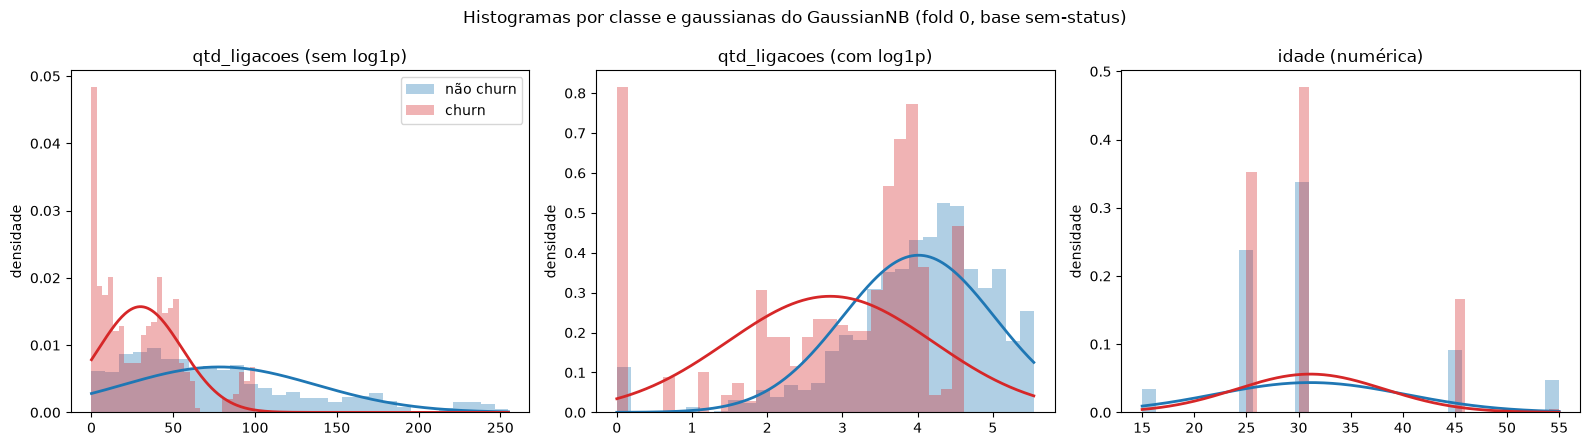

In [11]:
def normal(x, media, var):
    return np.exp(-(x - media) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)


X_sem = bases[False][0]
paineis = [
    ('sem-log1p', 'qtd_ligacoes', 'qtd_ligacoes (sem log1p)'),
    ('completo', 'qtd_ligacoes', 'qtd_ligacoes (com log1p)'),
    ('completo', 'idade', 'idade (numérica)'),
]
cores = {0: 'tab:blue', 1: 'tab:red'}
nomes = {0: 'não churn', 1: 'churn'}

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (config, col, titulo) in zip(eixos, paineis):
    Xc = atributos(X_sem, config)
    modelo = resultados[(config, 'sem-status')]['modelos'][0]
    j = list(modelo.feature_names_in_).index(col)
    grade_x = np.linspace(Xc[col].min(), Xc[col].max(), 400)
    for c in [0, 1]:
        ax.hist(Xc.loc[y == c, col], bins=30, density=True, alpha=0.35, color=cores[c], label=nomes[c])
        ax.plot(grade_x, normal(grade_x, modelo.theta_[c, j], modelo.var_[c, j]), color=cores[c], lw=2)
    ax.set_title(titulo)
    ax.set_ylabel('densidade')
eixos[0].legend()
fig.suptitle('Histogramas por classe e gaussianas do GaussianNB (fold 0, base sem-status)')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'nb-gaussianas.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusões

- **Desempenho geral**: o NB é o algoritmo mais fraco. A configuração escolhida (`sem-redundantes`, base sem `inativo`) tem recall 0,791 ± 0,069, especificidade 0,802 ± 0,016, F1 macro 0,712 ± 0,027 e PR-AUC 0,710 ± 0,096. Encontra quase o dobro dos churns da regra "reclamou → churn" (recall 0,426), mas não domina a regra "inativo → churn": tem mais recall (0,791 contra 0,729) e menos especificidade (0,802 contra 0,851). Com os priors 0,5 / 0,5, o custo aparece nos falsos alarmes: 476 clientes que ficam são apontados como churn, contra 93 churns perdidos.
- **Redundância**: tirar `segundos_uso` muda pouco. Na base sem `inativo`, a PR-AUC sobe 0,014 ± 0,033 (dentro da variação), o recall sobe 0,018 ± 0,018 e a especificidade cai 0,034 ± 0,010. O log loss melhora 0,161 ± 0,121, coerente com uma evidência a menos sendo contada. O efeito é pequeno porque a redundância vai além desse par: ligações, segundos, números distintos, SMS e `valor_cliente` medem o uso e caem juntos nos clientes churn (separação entre −0,65 e −1,01 desvios na tabela de parâmetros). Tirar um dos cinco não desfaz a dependência entre eles.
  - A `sem-redundantes` foi escolhida pela parcimônia: as três candidatas ficam a menos de um desvio da melhor, e ela é a que tem menos atributos (e também a maior PR-AUC).
- **`log1p`**: sem o log, o recall sobe (+0,159 ± 0,062), mas a especificidade despenca (−0,234 ± 0,034, de 0,836 para 0,602), o F1 macro cai 0,135 e o log loss sobe 0,768. A PR-AUC cai 0,026 ± 0,066, dentro da variação. A figura das gaussianas mostra o motivo: na escala original, a gaussiana do não churn é larga e achatada pela cauda longa, e a do churn é estreita e fica perto de zero. Qualquer cliente de uso baixo ou médio fica mais verossímil como churn, e daí vêm os falsos alarmes. Com o log, a maior parte dos clientes fica mais perto da normal, mas os clientes sem uso continuam num pico isolado em zero, que nenhuma das duas gaussianas representa bem.
- **Idade numérica**: as gaussianas captam o padrão só de leve. A do churn tem a mesma média que a do não churn (31,1 anos) e desvio menor (7,1 contra 9,1), o que dá uma razão de verossimilhança um pouco maior no meio e menor nos extremos. A separação entre as médias é praticamente nula (0,004 desvios). Uma variável com 5 valores e churn quase nulo em 15 e 55 anos fica mal representada por uma normal.
- **`inativo`**: é no NB que o atributo mais pesa. Na `sem-redundantes`, a base com `inativo` aumenta o recall em 0,101 ± 0,044 e a PR-AUC em 0,018 ± 0,015, e piora o log loss em 0,129. Como o NB multiplica as razões de verossimilhança, um binário com médias tão diferentes entre as classes entra com peso grande, somado às evidências de uso com as quais ele é correlacionado.
- **Desbalanceamento**: com os priors da base, o recall cai 0,074 ± 0,046 (sem `inativo`; de 101 para 134 churns perdidos) e a especificidade sobe 0,064 ± 0,016 (de 394 para 241 falsos alarmes). O log loss melhora 0,153 e o F1 macro sobe 0,036. A PR-AUC ficou idêntica nos 10 folds na base sem `inativo`, como previsto. Na base com `inativo` a diferença é de +0,001 ± 0,003, porque probabilidades que saturam em 0 ou 1 criam empates numéricos e mudam a ordem de poucos clientes. Os priors mudam só o ponto de operação.
- **Log loss**: as probabilidades do NB são mal calibradas. O log loss fica entre 0,96 e 1,26 nas configurações com `log1p`, contra 0,12 a 0,35 nos outros algoritmos, e acima de 0,433, o log loss de quem prevê 15,6% de churn para todos os clientes. Com os priors da base (0,967) continua alto. A causa principal é a evidência contada várias vezes: o produto de razões de verossimilhança correlacionadas empurra as probabilidades para 0 ou 1, e cada erro cometido com essa confiança custa caro no log loss.